## Assignment 4: Clustering algorithms
### Note: This Python assigment is quite different from the R version

### 80 points plus 6 extra credit for the KMeans portion.
### 14 extra credit points for the optional KNN portion.

In this assignment, we will build an unsupervised model to cluster some data using Kmeans, followed by a K-nearest neighbors classifier with the same dataset.

The data can be found here:

https://archive.ics.uci.edu/ml/datasets/glass+identification 

And the data description here: 

https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.names 

For this assignment, you'll need to look at the documentation for KMeans here:

https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

In [3]:
import matplotlib.pyplot as plt
import            numpy  as np
import            pandas as pd

import sklearn
from   sklearn.cluster         import KMeans
from   sklearn.decomposition   import PCA
from   sklearn.model_selection import train_test_split
from   sklearn.neighbors       import KNeighborsClassifier
from   sklearn.preprocessing   import MinMaxScaler

### Required Part A: K-Means Clustering 

In [6]:
# Task 1, 15 points: Get data and begin preprocessing
# 8 points: Setting the value of glassData correctly
# 3 points: Confirming the correct shape of the data
# 4 points: Displaying the resulting dataframe

# Download the data file from URL above into the same
# folder as this code file, but DO NOT use the 'IMPORT IN PYTHON' code
# that you will find at the first URL above. Also READ the
# data description!  Then read the the data into variable 'glassData' 
# Make sure that you have the expected number of observations, and if not,
# fix your code so it does.  How do you know how many rows there should be?
#  READ the data description file!  :-) 

glassData = pd.read_csv('/Users/oseyosmanyildiz/Downloads/glass+identification/glass.data', header=None)

# Add a line of code to verify that you have the correct number of observations (rows)

print(f"Shape of data: {glassData.shape}")
print(f"Number of rows: {glassData.shape[0]}")


# If the above line shows that you do NOT have the correct number, then modify
# the function you used to read it in so that it does not lose any rows.




# Now add a line to display that data frame

display(glassData)


Shape of data: (214, 11)
Number of rows: 214


,0,1,2,3,4,5,6,7,8,9,10
0,1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1
1,2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1
2,3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1
3,4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1
4,5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...
209,210,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7
210,211,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7
211,212,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7
212,213,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7


In [7]:
# Task 2, 20 points: Drop unneeded column and set column names

# 9  points: Drop column
# 10 points: Set meaningful column names, per info in data description
#           Note: It's ok to use abbreviations if you wish. 
#           You may have to search the web for examples of this
#           but make sure you include 'pandas' in your search.
#  1 point: Display the resulting dataframe

# In the previous cell output, notice that on the left you can see the row numbers, 
# and then in column '0' you also see the row numbers. Since they are just duplicates 
# of the row numbers, let's drop that column '0'. 

glassData = glassData.drop(columns=[0])

glassData.columns = ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'GlassType']

print("\nData with column names:")
display(glassData)




Data with column names:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,GlassType
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1
...,...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7


In [8]:
# Task 3: 10 points
# 5 points for grouping
# 5 points for counting and displaying the results

# Set the 'groupedTypes' variable to a groupby object created 
# from the GlassType variable of glassData
groupedTypes = glassData.groupby('GlassType')

# Now call the 'count' method of groupedTypes, passing no arguments.
# Since this is the last statement of the cell, it will show
# the results in the output

print("\nCounts by glass type:")
groupedTypes.count()




Counts by glass type:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
GlassType,,,,,,,,,
1,70,70,70,70,70,70,70,70,70
2,76,76,76,76,76,76,76,76,76
3,17,17,17,17,17,17,17,17,17
5,13,13,13,13,13,13,13,13,13
6,9,9,9,9,9,9,9,9,9
7,29,29,29,29,29,29,29,29,29


#### This output shows you several things.

1. It shows you how many types of glass there are
2. It will reveal if there are any features (attributes) with missing values.
3. It shows, for each type of glass, how many instances of each feature there are, e.g. you should see that there are 70 instances of the feature 'refractive index' for glass type 1.

Of course, you should already know the first two items from the data description file that you read.

In [9]:
# Task 4, 5 points: Kmeans model with random initialization
# 2.5 points for each line of code that you need to finish.

# Since we already know how many glass types there are (both from the 
# data description file and the previous cell), let's go ahead and 
# tell KMeans to create that many clusters. Also, use a random state of 34
# as well as verbose=1. Turning on verbose will make it print some
# intermediate results to the screen during the training. By default,
# KMeans will perform a maximum of 300 iterations,
# but it might perform far fewer than that if it 'converges' sooner.

# The metric used to measure convergence is called 'inertia', and it is
# simply the sum of the squared distances of each data point to 
# its assigned cluster centroid. Our EMC text refers to this 
# as the 'total sum of squares'.
# KMeans is very fast even if it goes 
# the full 300 iterations, unless the dataset is quite large.

# By default, KMeans will use 
# init = ‘k-means++’
# which I explain in class. However, for this first model, 
# let us change that and use 'random' initialization. 
# So just add that as one of the hyperparameter settings in the call to KMeans.
# Make sure you set the correct hyperparameter to the number of glass types,
# set verbose to 1, and use a random state of 34.

# With random initialization, it is easy to get a bad model (high inertia value),
# so we need to make it run the algorithm TEN times, choosing
# the best run after all 10 have been computed. Because of this, you'll see a lot
# of output, and you'll be able to see each of the 10 runs.
# My print statement at the very end will show you the lowest intertia value 
# from one of those 10 runs. It could be anywhere among the 10, but you should
# be able to find it easily by looking through the output.
# To make it run 10 times you have to set n_init to 10.

# Call KMeans with the hyperparameters and values just mentioned above.
km = KMeans(n_clusters=6, init='random', n_init=10, verbose=1, random_state=34)

# Call the km model's fit method on the glass data
kmRawRand = km.fit(glassData)

# Do not change the next line of code. It's MINE!
print ('\nFinal inertia of kmRawRand model with random initialization:', kmRawRand.inertia_)

Initialization complete
Iteration 0, inertia 965.9131979179.
Iteration 1, inertia 642.0206611751173.
Iteration 2, inertia 628.9579208730255.
Iteration 3, inertia 620.4470280320227.
Iteration 4, inertia 618.1605642860598.
Iteration 5, inertia 617.9135057301346.
Iteration 6, inertia 617.159729485763.
Iteration 7, inertia 615.6324520616025.
Iteration 8, inertia 614.1760310562585.
Iteration 9, inertia 613.3745430030264.
Iteration 10, inertia 613.2909915463874.
Converged at iteration 10: strict convergence.
Initialization complete
Iteration 0, inertia 2478.3840021121005.
Iteration 1, inertia 981.7368885378926.
Iteration 2, inertia 654.4737458532154.
Iteration 3, inertia 594.6434903272742.
Iteration 4, inertia 575.9483980743425.
Iteration 5, inertia 564.2569934949843.
Iteration 6, inertia 560.4693891162628.
Iteration 7, inertia 558.4648865794975.
Iteration 8, inertia 554.7983847601505.
Iteration 9, inertia 552.7485389000066.
Iteration 10, inertia 551.9686740600187.
Iteration 11, inertia 551.

In [10]:
# Task 5, 5 points: Kmeans model using smart initialization
# 3 points: Create your model and set kmSmartInit correctly, i.e. use ‘k-means++’
# 1 points: Fit the data and set kmRawSmart
# 1 points: Print the intertia with a message

# Next, create a new KMeans model that is exactly like the previous model, 
# except that this one will use k-means++ that I mention in our lecture. 
# Because k-means++ initialization is much better than random, 
# you may (but not necessarily) see an inertia value in this cell 
# that is better than the one printed in the previous cell.
# If so, it's a good demonstration how useful k-means++ is.
# Even if you do not obtain a better inertia score, you should
# see that the algorithm will converge in fewer iterations than
# you see in the previous cell, i.e. it will run faster.

kmSmartInit = KMeans(n_clusters=6, init='k-means++', n_init=10, verbose=1, random_state=34)

kmRawSmart  = kmSmartInit.fit(glassData)

print('\nFinal inertia of kmRawSmart model with k-means++ initialization:', kmRawSmart.inertia_)


Initialization complete
Iteration 0, inertia 705.4511231532997.
Iteration 1, inertia 507.7712342480176.
Iteration 2, inertia 497.7815978831657.
Iteration 3, inertia 495.6470333273.
Iteration 4, inertia 495.40740995479473.
Converged at iteration 4: strict convergence.
Initialization complete
Iteration 0, inertia 798.4864868788999.
Iteration 1, inertia 552.2303608065788.
Iteration 2, inertia 521.6846383306358.
Iteration 3, inertia 506.6647168684674.
Iteration 4, inertia 505.12550550489755.
Iteration 5, inertia 502.48829529283194.
Iteration 6, inertia 502.2442384611868.
Iteration 7, inertia 502.14156023166106.
Converged at iteration 7: strict convergence.
Initialization complete
Iteration 0, inertia 699.4461721886996.
Iteration 1, inertia 541.7195552344631.
Iteration 2, inertia 521.7938072569418.
Iteration 3, inertia 514.4605134428048.
Iteration 4, inertia 513.7900844842432.
Iteration 5, inertia 513.7046232868194.
Converged at iteration 5: strict convergence.
Initialization complete
Itera

In [11]:
# Task 6, 15 points: KMeans with normalized data
# 2 points each for the first 7 lines of code that you need to complete
# and 1 point for the final print statement.

# Now train a third KMeans model with scaled (normalized) data.
# As I explain in class, KMeans is sensitive to scaling
# because it's using Euclidean distance. Therefore you
# should always scale your data when using KMeans.

# We need to use sklearn's MinMaxScaler because
# scaling with StandardScaler gives a MUCH larger (worse) 
# inertia than the raw, unscaled data!

# You will need to consult:
# https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html
# for this cell. Just look at the example code to figure it out. Use fit_tranform 
# with the scaler to set glassScaled.

scaler      = MinMaxScaler()
glassScaled = scaler.fit_transform(glassData)

# I'm giving you some code next. Don't change it.
# You will see that the min/max values for the
# different features vary a lot, which is why
# it will interfere with the distance calculation.
# By normalizing the data, each feature's values
# will be transformed to the range between 0 and 1,
# making the distance calculation comparable for each feature.

print('(min, max) values for each feature in raw, pre-normalized data:')
for pair in list(zip(scaler.data_min_, scaler.data_max_)):
    print(pair)

print('\nRunning KMeans...\n')

# Now add some code for a new KMeans model and use the fit method
# of kmScaled on the glassScaled data that you just created, saving
# the result into kmScaledFitted

kmScaled       = KMeans(n_clusters=6, init='k-means++', n_init=10, verbose=1, random_state=34)
kmScaledFitted = kmScaled.fit(glassData)

print ('\nFinal inertia of KMeans on scaled data:', kmScaledFitted.inertia_)

# Now use the transform method of the kmScaled model on the glassScaled data as input.
# This will return a numpy array. Each top element of that array
# will be a vector of 6 numbers. Each number will show the distance
# for that row of your original dataframe to the centroid that was
# assigned to it by the clustering algorithm.

kmScaledTransformed = kmScaled.transform(glassData)

# Print the value of kmScaledTransformed for rows 14 through 34 (i.e. 14:34)
# along with your own message explaining what we are looking at.

print("\nDistances from each observation (rows 14-34) to all 6 cluster centroids:")
print(kmScaledTransformed[14:34])

# Now use the predict method kmScaledFitted on the glassScaled data, printing the same 14 to 34 values
# to the screen. 

assignedCentroids = kmScaledFitted.predict(glassScaled)

# Now print the value of assignedCentroids with a message that tells us 
# what the output means, in other words explain what assignedCentroids means.
# For each integer that you see from the next print statement, you should be able 
# to confirm that it refers to the index of the smallest distance for the corresponding row
# in the preceding print statement.
# This next line is worth 1 point.

print("\nAssigned centroid (cluster) for each observation (rows 14-34):")
print("These numbers indicate which cluster (0-5) each observation was assigned to:")
print(assignedCentroids[14:34])

(min, max) values for each feature in raw, pre-normalized data:
(np.float64(1.51115), np.float64(1.53393))
(np.float64(10.73), np.float64(17.38))
(np.float64(0.0), np.float64(4.49))
(np.float64(0.29), np.float64(3.5))
(np.float64(69.81), np.float64(75.41))
(np.float64(0.0), np.float64(6.21))
(np.float64(5.43), np.float64(16.19))
(np.float64(0.0), np.float64(3.15))
(np.float64(0.0), np.float64(0.51))
(np.float64(1.0), np.float64(7.0))

Running KMeans...

Initialization complete
Iteration 0, inertia 705.4511231532997.
Iteration 1, inertia 507.7712342480176.
Iteration 2, inertia 497.7815978831657.
Iteration 3, inertia 495.6470333273.
Iteration 4, inertia 495.40740995479473.
Converged at iteration 4: strict convergence.
Initialization complete
Iteration 0, inertia 798.4864868788999.
Iteration 1, inertia 552.2303608065788.
Iteration 2, inertia 521.6846383306358.
Iteration 3, inertia 506.6647168684674.
Iteration 4, inertia 505.12550550489755.
Iteration 5, inertia 502.48829529283194.
Iteratio

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


### You should notice in your output that normalizing the data results in significantly smaller inertia values than in the earlier models.

All centroid assignments for the scaled glass data:
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Counts for each centroid:
 [[  1 214]]


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


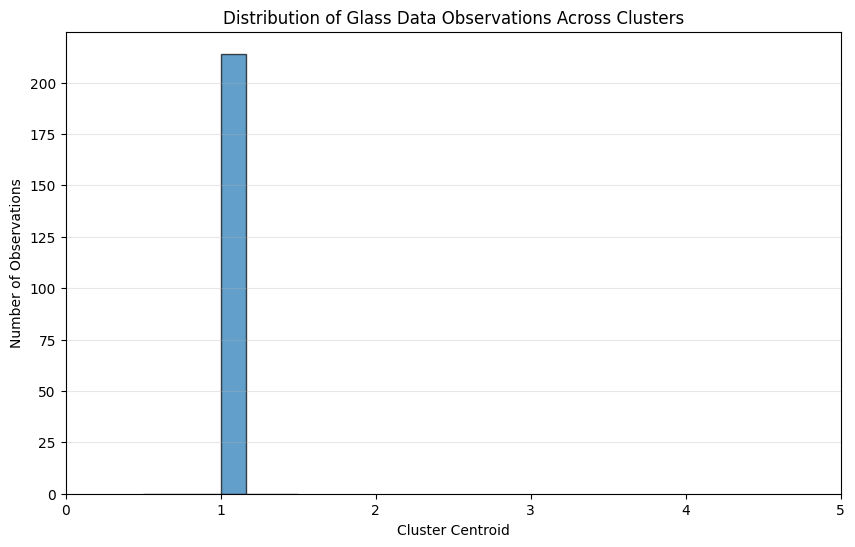

In [12]:
# Task 7, 10 points: Creating a histogram of data observations assigned to each centroid

# Task 3: 10 points
# 5 points for setting allCentroids
# 5 points for the histogram

# For the scaled and fitted model, use (again) its predict method 
# on ALL the rows of glassScaled, and save it into allCentroids

allCentroids = kmScaledFitted.predict(glassScaled)

# Do NOT change the next 3 lines of code
print('All centroid assignments for the scaled glass data:\n', allCentroids) 
# Make a kind of numpy table of the counts
centroid, counts = np.unique(allCentroids, return_counts=True) 
# Show the table
print('Counts for each centroid:\n', np.asarray((centroid, counts)).T)  

##### Put YOUR code for the histogram below ######
plt.figure(figsize=(10, 6))
plt.hist(allCentroids, bins=6, edgecolor='black', alpha=0.7)
plt.xlabel('Cluster Centroid')
plt.ylabel('Number of Observations')
plt.title('Distribution of Glass Data Observations Across Clusters')
plt.xticks(range(6))
plt.grid(axis='y', alpha=0.3)
plt.show()
# Create and display a histogram of allCentroids
# It can be very basic OR, if you like, you can make it more pleasing to the eye.



Initialization complete
Iteration 0, inertia 248.26270286740146.
Iteration 1, inertia 183.6883571398175.
Iteration 2, inertia 181.7576937035249.
Iteration 3, inertia 181.39229716265314.
Iteration 4, inertia 179.06312549840518.
Iteration 5, inertia 177.62542847575963.
Iteration 6, inertia 174.99791030596697.
Iteration 7, inertia 173.74794875190958.
Converged at iteration 7: strict convergence.
Initialization complete
Iteration 0, inertia 267.30150915920757.
Iteration 1, inertia 188.08217752344333.
Iteration 2, inertia 169.79916656648282.
Iteration 3, inertia 166.19145203686432.
Iteration 4, inertia 166.1048351945513.
Converged at iteration 4: center shift 0.0003878644376216151 within tolerance 0.0004329565113618527.
Initialization complete
Iteration 0, inertia 230.33717208585523.
Iteration 1, inertia 159.7894795949542.
Iteration 2, inertia 153.2039741886643.
Iteration 3, inertia 152.95694780719325.
Iteration 4, inertia 152.64636507242813.
Converged at iteration 4: center shift 0.0002101

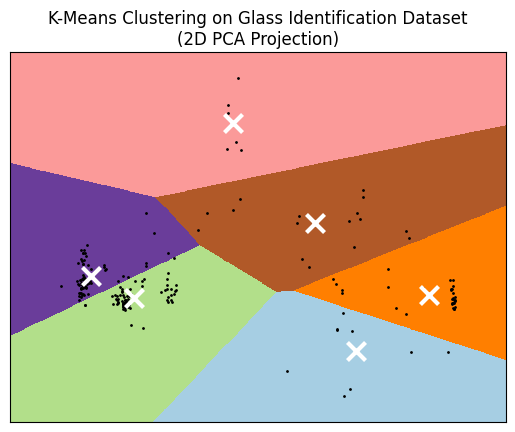

In [13]:
# Extra credit, 6 points: Print a visualization of the cluster boundaries

# NOTE: You will need to look at the example visualization
# in the sklearn documentation at: 
# https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_digits.html

# Copy that code and put it into this cell. Then change it as follows:
# But before you decide to panic, this task is actually QUITE EASY
# because you only need to change a very small amount of code
# at that URL to get it to work for your data.

# 2 points: Use the glassData (Don't use the normalized glass data)
# 2 points: Set the same number of KMeans clusters as you did above
#           and also use k-means++, 10 iterations, verbose turned ON, and random state 34.
# 2 points: Change the wording of the plot title to make
#           it consistent with OUR dataset, not the one you see 
#           in the example code from sklearn that you copied.

# Compute the first 2 principal components of the data using PCA 
# so that we can create a model that we can plot in 2 dimensions 
# This cell uses the raw data, the next cell uses the scaled data

data         = glassData ########################################## PUT YOUR CODE HERE #####
numClusters  = 6 ########################################## PUT YOUR CODE HERE #####
reduced_data = PCA(n_components=2).fit_transform(data)

############################ ADD SETTINGS ON THE NEXT LINE OF CODE HERE INSIDE THE EMPTY PARENTHESES 
############################ TO SET ' n_init', 'init', 'n_clusters', 'verbose', AND 'random_state'
############################ AS DESCRIBED ABOVE
kmeans = KMeans(n_clusters=numClusters, init='k-means++', n_init=10, 
                verbose=1, random_state=34)
kmeans.fit(reduced_data)

# Step size of the mesh. Decrease to increase the quality of the VQ.
h = 0.02  # point in the mesh [x_min, x_max]x[y_min, y_max].

# Plot the decision boundary. For that, we will assign a color to each
x_min, x_max = reduced_data[:, 0].min() - 1, reduced_data[:, 0].max() + 1
y_min, y_max = reduced_data[:, 1].min() - 1, reduced_data[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Obtain labels for each point in mesh. Use last trained model.
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])

# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.figure(1)
plt.clf()
plt.imshow(
    Z,
    interpolation="nearest",
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    cmap=plt.cm.Paired,
    aspect="auto",
    origin="lower",
)

plt.plot(reduced_data[:, 0], reduced_data[:, 1], "k.", markersize=2)
# Plot the centroids as a white X
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="x",
    s=169,
    linewidths=3,
    color="w",
    zorder=10,
)
plt.title("K-Means Clustering on Glass Identification Dataset\n(2D PCA Projection)") ########################################## SET THE TITLE HERE TO REFER TO OUR DATA )
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xticks(())
plt.yticks(())
plt.show()

#### Notice that we get VERY different values for the inertia 
than we got earlier, and that is because we only have TWO
features here (the first two principal components) whereas
previously we used all 10 of the original features in the data.

However, you will also notice that, even though I asked you to use the UNnormalized glassData,
the Principal Component data gives us significantly smaller (better) inertia values
than you got above on the same unnormalized data!

But you will also notice that the six 'clusters' do not really appear to be very good clusters, in the sense that only a few of them are dense and clearly separated from the others.

### Optional Part B: K-nearest neighbors, 20 extra credit points.

For this optional part you should consult the scikit-learn documentation for KNN at:

https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

In [14]:
# Split Data for Classifier: 4 points

# We will create a K-nearest neighbors classifier 
# for the UNscaled glassData, but first we need to 
# separate the GlassType column, which is the target variable
# from the rest of the data, which are the predictors. Then
# we will create our training and test datasets. You have
# already done something similar in a previous assignment

X = glassData.drop(columns=['GlassType'])
y = glassData['GlassType']

print("\nPredictor variables (X):")
display(X)
print("\nTarget variable (y):")
display(y)

# Now we can split our data into training and test subsets. 
# Let's try a 70/30 split with a random state of 34
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=34)
print(f"\nTraining set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

# Create the untrained classifier using 5 nearest neighbors. 
# 5 is the default, but let's make it explicit.


Predictor variables (X):


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0
...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0



Target variable (y):


0      1
1      1
2      1
3      1
4      1
      ..
209    7
210    7
211    7
212    7
213    7
Name: GlassType, Length: 214, dtype: int64


Training set size: 149
Test set size: 65


In [15]:
# Basic KNN Model: 4 points

# Build KNN model on the above training data  
# using all default values for KNeighborsClassifier.
# Evaluate the test data accuracy using the score method 
# of the trained model. Then print an explanatory message that 
# refers to the value for k and the test score.

k   = 5 # This IS the default value for k, but we will make it explicit with this variable

knn = KNeighborsClassifier(n_neighbors=k)

knn.fit(X_train, y_train)


knn5Acc = knn5Acc = knn.score(X_test, y_test)

print(f"\nKNN Model with k={k}: Test Accuracy = {knn5Acc:.4f}")


KNN Model with k=5: Test Accuracy = 0.6154


In [16]:
# Find best value for k: 6 points

# Put your code into a loop that sets k to the values from 1 to 10.
# In your code, keep track of the highest accuracy value
# and the k value that resulted in that best score.

# After the loop is done, use those two saved values
# for k and best score and print both to the output
# along with a brief explanatory message.

######## Put your code below for the loop and the final print statement #######

best_k = 1
best_score = 0

print("\nTesting different values of k:")
for k in range(1, 11):
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    score = knn_temp.score(X_test, y_test)
    print(f"k={k}: Accuracy = {score:.4f}")
    
    if score > best_score:
        best_score = score
        best_k = k

print(f"\nBest k value: {best_k}")
print(f"Best test accuracy: {best_score:.4f}")



Testing different values of k:
k=1: Accuracy = 0.6000
k=2: Accuracy = 0.6308
k=3: Accuracy = 0.6154
k=4: Accuracy = 0.6462
k=5: Accuracy = 0.6154
k=6: Accuracy = 0.5385
k=7: Accuracy = 0.5538
k=8: Accuracy = 0.5692
k=9: Accuracy = 0.6154
k=10: Accuracy = 0.6000

Best k value: 4
Best test accuracy: 0.6462
